# Моделирование маршрутизации в Mesh-сети LoRa

Ноутбук для экспериментов с методами маршрутизации в радиосети с ограниченной пропускной способностью. Узлы бывают **стационарными** и **подвижными**. В обоих вариантах топология может быть **динамической**: заданные или случайные узлы пропадают и появляются снова.

**Как пользоваться**

1. Выполните все ячейки сверху вниз: *Kernel → Restart & Run All*.
2. Параметры собраны в отдельных ячейках с пометкой ⚙️. Что в них задаётся:
   - радио (LoRa) — раздел 1;
   - логика и ограничения узла — раздел 2;
   - канал — раздел 3;
   - топологии — раздел 5;
   - динамика узлов — раздел 6;
   - трафик и сценарий — раздел 7.
3. Эксперименты начинаются с раздела 10. Каждый из них — готовый шаблон, его можно копировать и менять.

Зависимости: Python 3.10+, `pandas`, `matplotlib`. Запуск через uv описан в `README.md`; кратко: `uv sync`, затем `uv run jupyter lab`. Симулятор написан на чистом Python: дискретно-событийное ядро на очереди с приоритетом.

**Содержание**

0. Допущения модели
1. Радио LoRa и время в эфире (ToA)
2. Логика узла и ограничения
3. Модель канала
4. Методы маршрутизации
5. Топологии: стационарные и подвижные
6. Динамика: пропадание и появление узлов
7. Трафик и сценарий
8. Ядро симулятора
9. Метрики и графики
10. Эксперименты

## 0. Допущения модели

Данные приближены к реальным: время в эфире считается по формуле Semtech для LoRa, токи потребления радио — по данным Semtech для SX1262, микроконтроллера — ориентировочные для nRF52840 или ESP32.

| № | Допущение | Как реализовано |
|---|---|---|
| 1 | Одна частота и один канал в пределах одного сегмента | Все узлы делят общий эфир. Если два кадра перекрываются у приёмника, оба теряются |
| 2 | Связь полудуплексная | Пока узел передаёт, он не принимает. Начало своей передачи портит текущий приём |
| 3 | Стоимость ребра — время передачи по нему | Стоимость перехода = (ToA кадра + время обработки) × ETX канала. Физическое распространение d/c ≈ 3 мкс/км пренебрежимо мало и не учитывается |
| 4 | Время обработки пакета на микроконтроллере — фиксированная величина | `McuConfig`: обработка принятого кадра `t_rx_proc_s` и подготовка кадра к передаче `t_tx_prep_s`. MCU выполняет задачи по одной: пока он занят, следующий пакет ждёт |
| 5 | Связь есть, если узлы ближе радиуса R | Модель «единичного диска»; качество канала падает с расстоянием, ETX = 1/p² |
| 6 | Bluetooth-участок (телефон ↔ узел) не моделируется | Пакеты появляются в очереди узла-источника. Участок Bluetooth не занимает эфир LoRa |

**Режимы узла:** 1 — дежурный приём, 2 — передача, 3* — сон (необязательный, по умолчанию выключен).

**Ограничения узла:** энергия, память, эфирное время.

In [19]:
import math, heapq, random, bisect, itertools
from collections import deque, OrderedDict, Counter
from dataclasses import dataclass, field, replace
from typing import Optional

import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

## 1. Радио LoRa и время в эфире (ToA) ⚙️

Радиомодуль — **Semtech SX1262**: SF5…SF12, мощность до +22 dBm. Время в эфире считается по формуле из даташита SX1261/2 (раздел 6.1.4 «LoRa Time-on-Air»):

$$T_{sym} = \frac{2^{SF}}{BW}$$

Для SF7…SF12:
$$N = (n_{preamble} + 4{,}25) + 8 + \left\lceil \frac{\max(8PL + 16\,CRC - 4SF + 8 + 20\,H,\ 0)}{4\,(SF - 2\,LDRO)} \right\rceil (CR + 4)$$

Для SF5 и SF6:
$$N = (n_{preamble} + 6{,}25) + 8 + \left\lceil \frac{\max(8PL + 16\,CRC - 4SF + 20\,H,\ 0)}{4\,SF} \right\rceil (CR + 4)$$

$$ToA = N \cdot T_{sym}$$

Обозначения:
- PL — длина кадра в байтах;
- H = 1 при явном заголовке;
- CRC = 1, если CRC включён;
- CR = 1…4 (4/5…4/8);
- LDRO = 1 при оптимизации низкой скорости. Включается автоматически при $T_{sym}$ ≥ 16,38 мс: SF11 и SF12 на BW 125 кГц.

Для SF7…SF12 результат совпадает с формулой для SX127x. Пример: SF7, BW 125 кГц, 20 байт — 56,6 мс.

**Токи SX1262**, режим DC-DC:
- передача +22 dBm — 118 мА;
- приём LoRa, BW 125 кГц — 4,6 мА;
- сон с сохранением конфигурации — порядка 0,6 мкА (ориентировочно).

Источники: [Semtech SX1262](https://www.semtech.com/products/wireless-rf/lora-connect/sx1262), [руководство EBYTE E22](https://cdn.hackaday.io/files/1614916909230944/E22_Usermanual_EN_v1.10.pdf). Для модуля E22-900M22S там указаны 119 мА на передачу, 5,0 мА на приём и 185 нА в выключенном состоянии.

При меньшей мощности передачи или в режиме LDO возьмите токи из таблиц даташита своего модуля.

In [20]:
@dataclass
class RadioConfig:
    """⚙️ Параметры радио: Semtech SX1262."""
    chip: str = "SX1262"
    sf: int = 7                      # spreading factor, 5..12
    bw_hz: float = 125_000           # полоса, Гц
    cr: int = 1                      # 1..4 -> 4/5..4/8
    preamble_symbols: int = 8
    explicit_header: bool = True
    crc_on: bool = True
    low_dr_optimize: Optional[bool] = None   # None = авто (T_sym >= 16,38 мс)
    voltage_v: float = 3.3
    tx_power_dbm: int = 22
    i_tx_ma: float = 118.0           # передача +22 dBm, DC-DC
    i_rx_ma: float = 4.6             # дежурный приём LoRa, BW 125 кГц, DC-DC
    i_sleep_ma: float = 0.0006       # сон с сохранением конфигурации, ~0,6 мкА (ориентировочно)


def lora_toa(payload_bytes: int, r: RadioConfig) -> float:
    """Время в эфире кадра LoRa для SX126x, с (даташит SX1261/2, раздел 6.1.4)."""
    assert 5 <= r.sf <= 12, "SX1262 поддерживает SF5..SF12"
    t_sym = (2 ** r.sf) / r.bw_hz
    ldro = r.low_dr_optimize if r.low_dr_optimize is not None else (t_sym >= 0.01638)
    h = 1 if r.explicit_header else 0
    crc = 1 if r.crc_on else 0
    if r.sf in (5, 6):
        n_pre = r.preamble_symbols + 6.25
        num = 8 * payload_bytes + 16 * crc - 4 * r.sf + 20 * h
        den = 4 * r.sf
    else:
        n_pre = r.preamble_symbols + 4.25
        num = 8 * payload_bytes + 16 * crc - 4 * r.sf + 8 + 20 * h
        den = 4 * (r.sf - 2 * int(ldro))
    n_payload = 8 + math.ceil(max(num, 0) / den) * (r.cr + 4)
    return (n_pre + n_payload) * t_sym


assert abs(lora_toa(20, RadioConfig(sf=7)) - 0.05658) < 1e-4   # контрольное значение 56,6 мс


# Справочная таблица ToA, мс
pd.DataFrame(
    {f"{pl} байт": [round(lora_toa(pl, RadioConfig(sf=sf)) * 1000, 1) for sf in range(5, 13)]
     for pl in (6, 20, 32, 64)},
    index=[f"SF{sf}, BW 125 кГц" for sf in range(5, 13)],
)

,6 байт,20 байт,32 байт,64 байт
"SF5, BW 125 кГц",10.8,17.2,23.6,40.3
"SF6, BW 125 кГц",19.1,31.9,42.1,67.7
"SF7, BW 125 кГц",36.1,56.6,71.9,118.0
"SF8, BW 125 кГц",62.0,102.9,133.6,215.6
"SF9, BW 125 кГц",123.9,185.3,246.8,390.1
"SF10, BW 125 кГц",247.8,370.7,452.6,698.4
"SF11, BW 125 кГц",495.6,741.4,987.1,1560.6
"SF12, BW 125 кГц",991.2,1318.9,1810.4,2793.5


## 2. Логика узла и ограничения ⚙️

### Состояния узла

| Состояние | Что делает узел | Ток |
|---|---|---|
| **RX** — дежурный приём | Слушает эфир и принимает кадры. Каждый принятый кадр передаётся микроконтроллеру на обработку | `i_rx_ma` |
| **TX** — передача | Передаёт один кадр длительностью ToA, ничего не принимает (полудуплекс) | `i_tx_ma` |
| **SLEEP** — сон (3*, по желанию) | Не принимает и не передаёт. Просыпается по расписанию: период `sleep_period_s`, доля бодрствования `awake_fraction` | `i_sleep_ma` |
| **OFF** — узел пропал | Выключен сценарием динамики. Очередь, кэш и таблицы стираются (энергозависимая память) | 0 |
| **DEAD** — батарея исчерпана | Узел выключен навсегда | 0 |

### Переходы

```
           кадр в очереди, канал свободен,          конец кадра
           лимит эфира не превышен
   RX ───────────────────────────────────▶ TX ─────────────────▶ RX (или SLEEP, если пора спать)
   │ ▲
   │ └── пробуждение по расписанию ── SLEEP ◀── время сна (только если sleep_enabled)
   │
   └── сценарий динамики ──▶ OFF ──▶ RX (узел вернулся)
   любое состояние ── энергия исчерпана ──▶ DEAD
```

### Микроконтроллер (MCU)

Радио SX1262 только принимает и передаёт кадры. Всё остальное делает микроконтроллер, и на это уходит время.

- **Обработка принятого кадра** — `t_rx_proc_s`. MCU получает прерывание, читает кадр из буфера радио по SPI, разбирает заголовок, проверяет кэш и принимает решение. У LoRa нет аппаратной фильтрации адресов, поэтому MCU обрабатывает и чужие кадры, которые услышал узел.
- **Подготовка кадра к передаче** — `t_tx_prep_s`: сформировать заголовок, записать кадр в буфер радио, дать команду на передачу. Это касается и DATA, и ACK.
- **Одна задача за раз.** Пока MCU занят, следующая задача ждёт. Очередь задач ограничена `mcu.queue_capacity` — это тоже ограничение памяти. При переполнении кадр теряется (`mcu_overflow`).
- **Энергия MCU** — `i_active_ma` во время задач и `i_idle_ma` в остальное время, пока узел включён. Энергия узла = радио + MCU.

Готовые профили — в `MCU_PRESETS`. Значения ориентировочные: на реальной плате времена лучше измерить, например переключая GPIO и глядя на осциллограф.

### Обработка принятого кадра (после окончания приёма и обработки на MCU)

1. **ACK для меня** — снять ожидание подтверждения и передать следующий кадр из очереди.
2. **DATA, затопление** — если ID пакета уже есть в кэше, отбросить дубликат. Если узел — получатель, доставить. Иначе, если `hop_limit > 1`, поставить копию с `hop_limit − 1` в очередь после случайной задержки `flood_jitter_s`.
3. **DATA, адресная передача** (Дейкстра, DP) — кадр не мне: игнорировать, но он всё равно занимал приёмник. Кадр мне: сразу отправить ACK. Если это дубликат (потерялся наш ACK), дальше не пересылать. Если узел — получатель, доставить. Иначе переслать следующему узлу маршрута, если `hop_limit > 1`; если нет — пакет отброшен, эфир потрачен впустую.

### Передача кадра

1. Взять первый кадр из очереди (FIFO).
2. **Подготовка на MCU** — `t_tx_prep_s`, плюс ожидание, если MCU занят.
3. **Лимит эфира**: если за последние `duty_cycle_window_s` секунд узел уже занимал эфир больше `duty_cycle_limit`, отложить передачу.
4. **Прослушивание перед передачей** (CSMA): если узел сейчас слышит чужую передачу, подождать случайное время `csma_backoff_s`. Не больше `csma_max_attempts` раз, затем передавать всё равно.
5. Передать. Для адресного кадра ждать ACK `t_rx_proc + t_tx_prep + ToA(ACK) + ack_guard_s`. Без ACK повторить до `max_retries` раз, затем отбросить пакет с причиной «обрыв канала».

### Ограничения узла

| Ограничение | Параметр | Что происходит при нарушении |
|---|---|---|
| **1. Энергия** | `battery_j` — запас энергии, Дж | Расход = радио (время в каждом состоянии × ток × напряжение) + MCU (активное время и простой). Энергия кончилась — узел переходит в DEAD |
| **2. Память** | `queue_capacity` — очередь на передачу, пакетов | Очередь полна — новый пакет отброшен (`queue_overflow`) |
| | `mcu.queue_capacity` — очередь задач MCU | Кадр, пришедший при полной очереди MCU, теряется (`mcu_overflow`) |
| | `seen_cache_capacity` — кэш ID виденных пакетов | Кэш LRU: старые ID вытесняются, и узел может повторно переслать уже виденный пакет |
| **3. Эфирное время** | `duty_cycle_limit`, `duty_cycle_window_s` | Передача откладывается, пока доля эфира в окне не опустится ниже лимита. В диапазоне EU868 по правилам 1 % в час. По умолчанию здесь 10 % в окне 60 с, чтобы ограничение было заметно на коротком прогоне |

In [21]:
@dataclass
class McuConfig:
    """⚙️ Микроконтроллер: время обработки и потребление (допущение 4)."""
    name: str = "nRF52840"
    t_rx_proc_s: float = 0.004         # обработка принятого кадра, с
    t_tx_prep_s: float = 0.002         # подготовка кадра к передаче (DATA и ACK), с
    queue_capacity: int = 8            # очередь задач MCU (ограничение памяти)
    i_active_ma: float = 3.3           # ток во время обработки
    i_idle_ma: float = 0.003           # ток в простое, узел включён


# Ориентировочные профили; замените измерениями своей платы
MCU_PRESETS = {
    "nRF52840":  McuConfig("nRF52840 (RAK4631)", 0.004, 0.002, 8, 3.3, 0.003),       # 64 МГц, System ON idle
    "ESP32-S3":  McuConfig("ESP32-S3 (Heltec V3)", 0.002, 0.001, 16, 45.0, 0.8),     # 240 МГц, light sleep
    "slow_mcu":  McuConfig("медленный MCU", 0.020, 0.010, 4, 5.0, 0.01),             # для стресс-проверки
}


@dataclass
class NodeConfig:
    """⚙️ Логика и ограничения узла."""
    # Микроконтроллер (допущение 4)
    mcu: McuConfig = field(default_factory=McuConfig)

    # Ограничение 1: энергия
    battery_j: float = float("inf")    # запас энергии, Дж (inf = без ограничения)

    # Ограничение 2: память
    queue_capacity: int = 16           # очередь на передачу, пакетов
    seen_cache_capacity: int = 64      # кэш ID виденных пакетов (LRU)

    # Ограничение 3: эфирное время
    duty_cycle_limit: float = 0.10     # доля времени в передаче за окно
    duty_cycle_window_s: float = 60.0

    # Доступ к каналу
    csma: bool = True
    csma_backoff_s: tuple = (0.01, 0.10)
    csma_max_attempts: int = 8
    flood_jitter_s: tuple = (0.0, 0.20)   # задержка перед ретрансляцией при затоплении

    # Надёжная адресная передача
    max_retries: int = 3
    ack_guard_s: float = 0.03

    # 3*. Режим сна (по умолчанию выключен)
    sleep_enabled: bool = False
    sleep_period_s: float = 10.0
    awake_fraction: float = 0.5

    # Размеры кадров, байт
    header_bytes: int = 12             # адреса, ID пакета, HopLimit, тип
    route_bytes_per_hop: int = 1       # маршрут в заголовке (для адресной передачи)
    ack_bytes: int = 6

In [22]:
class S:
    """Состояния узла."""
    RX, TX, SLEEP, OFF, DEAD = "RX", "TX", "SLEEP", "OFF", "DEAD"


@dataclass
class Frame:
    kind: str                         # "DATA" или "ACK"
    pid: int                          # ID пакета (сквозной)
    src: int                          # источник
    dst: int                          # получатель
    hop_limit: int
    link_src: Optional[int] = None    # кто передаёт этот кадр
    link_dst: Optional[int] = None    # кому адресован (None = широковещательно)
    route: Optional[list] = None      # маршрут для адресной передачи
    idx: int = 0                      # позиция передающего узла в маршруте
    size: int = 0                     # длина кадра, байт
    hops: int = 0                     # сколько переходов уже пройдено


class Node:
    """Узел сети: состояние, учёт энергии и проверка ограничений.
    Решения о маршрутизации принимает симулятор (раздел 8), узел хранит данные."""

    def __init__(self, nid, cfg: NodeConfig, radio: RadioConfig):
        self.id, self.cfg, self.radio = nid, cfg, radio
        self.state, self.state_since = S.RX, 0.0
        self.energy_j = 0.0
        self.time_in = Counter()
        self.queue = deque()             # ограничение 2: очередь
        self.seen = OrderedDict()        # ограничение 2: кэш ID
        self.tx_log = deque()            # ограничение 3: (начало, длительность)
        self.incoming = {}               # tx_id -> "ok" | "collision" | "halfduplex" | "not_listening"
        self.busy = False                # передаёт, ждёт ACK или выжидает паузу
        self.current = None              # кадр, ожидающий ACK
        self.ack_wait_id = None
        self.retries = 0
        self.csma_attempts = 0
        self.awake = True
        self.epoch = 0                   # растёт при выключении: старые события игнорируются
        self.airtime_s = 0.0
        self.tx_count = 0
        self.t_death = None
        self.mcu_busy_until = 0.0        # MCU свободен с этого момента
        self.mcu_pending = 0             # задач в очереди MCU
        self.mcu_active_s = 0.0          # суммарное время работы MCU

    @property
    def alive(self):
        return self.state not in (S.OFF, S.DEAD)

    @property
    def can_receive(self):
        return self.state == S.RX

    # Энергия (ограничение 1)
    def _current_ma(self, st):
        return {S.RX: self.radio.i_rx_ma, S.TX: self.radio.i_tx_ma,
                S.SLEEP: self.radio.i_sleep_ma}.get(st, 0.0)

    def set_state(self, new, t):
        dt = t - self.state_since
        self.time_in[self.state] += dt
        self.energy_j += self.radio.voltage_v * self._current_ma(self.state) / 1000 * dt
        self.state, self.state_since = new, t

    def alive_time(self, t):
        base = sum(v for k, v in self.time_in.items() if k in (S.RX, S.TX, S.SLEEP))
        return base + (t - self.state_since if self.alive else 0.0)

    def mcu_energy_j(self, t):
        m = self.cfg.mcu
        idle = max(self.alive_time(t) - self.mcu_active_s, 0.0)
        return self.radio.voltage_v * (m.i_active_ma * self.mcu_active_s + m.i_idle_ma * idle) / 1000

    def total_energy_j(self, t):
        return self.energy_j + self.mcu_energy_j(t)

    def battery_empty(self, t):
        return self.total_energy_j(t) >= self.cfg.battery_j

    # Память (ограничение 2)
    def mark_seen(self, pid) -> bool:
        """True, если пакет новый."""
        if pid in self.seen:
            self.seen.move_to_end(pid)
            return False
        self.seen[pid] = True
        if len(self.seen) > self.cfg.seen_cache_capacity:
            self.seen.popitem(last=False)
        return True

    def enqueue(self, frame) -> bool:
        if len(self.queue) >= self.cfg.queue_capacity:
            return False
        self.queue.append(frame)
        return True

    # Эфирное время (ограничение 3)
    def dc_wait(self, t, dur) -> float:
        """Сколько ждать, чтобы передача длительностью dur уложилась в лимит."""
        W = self.cfg.duty_cycle_window_s
        budget = self.cfg.duty_cycle_limit * W
        while self.tx_log and self.tx_log[0][0] + self.tx_log[0][1] <= t - W:
            self.tx_log.popleft()
        used = sum(min(d, s + d - (t - W)) for s, d in self.tx_log)
        if used + dur <= budget or not self.tx_log:
            return 0.0
        s, d = self.tx_log[0]
        return max(s + d + W - t, 1e-3)

    def reset_volatile(self):
        """Выключение: энергозависимая память стирается."""
        self.queue.clear(); self.seen.clear(); self.incoming.clear()
        self.busy = False; self.current = None; self.ack_wait_id = None
        self.retries = 0; self.csma_attempts = 0
        self.mcu_pending = 0

## 3. Модель канала ⚙️

- **Связность.** Канал между узлами есть, если расстояние d ≤ R.
- **Качество.** Вероятность успешного приёма кадра p(d) равна `p_max` до расстояния `d0_frac`·R, затем квадратично падает до `p_min` на границе R.
- **ETX** — ожидаемое число передач с учётом потерь в обе стороны (кадр и ACK): ETX = 1/p².
- **Коллизии.** Если у приёмника перекрываются два кадра, теряются оба. Эффект захвата не моделируется. Узлы дальше R не мешают.
- **Полудуплекс.** Начало собственной передачи портит текущий приём.

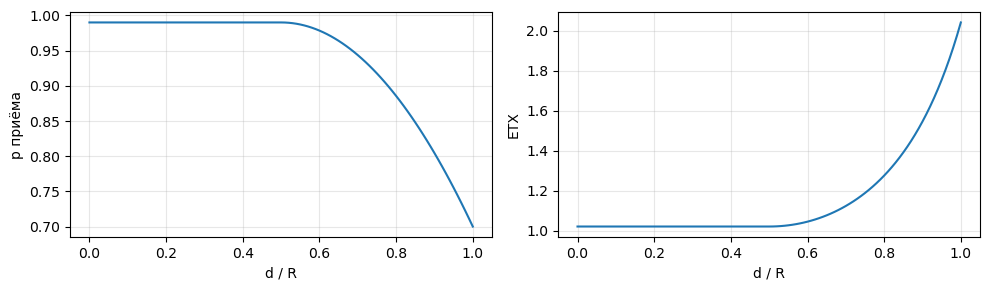

In [23]:
@dataclass
class ChannelConfig:
    """⚙️ Канал."""
    p_max: float = 0.99      # вероятность приёма вблизи
    p_min: float = 0.70      # вероятность приёма на границе R
    d0_frac: float = 0.5     # до какой доли R качество максимально


def link_pdr(d, R, ch: ChannelConfig) -> float:
    x = d / R
    if x <= ch.d0_frac:
        return ch.p_max
    if x >= 1:
        return ch.p_min
    f = (x - ch.d0_frac) / (1 - ch.d0_frac)
    return ch.p_max - (ch.p_max - ch.p_min) * f * f


def etx(d, R, ch: ChannelConfig) -> float:
    p = link_pdr(d, R, ch)
    return 1.0 / (p * p)


# Как качество зависит от расстояния
_ch = ChannelConfig()
_x = [i / 100 for i in range(0, 101)]
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(_x, [link_pdr(x, 1, _ch) for x in _x]); ax[0].set_xlabel("d / R"); ax[0].set_ylabel("p приёма")
ax[1].plot(_x, [etx(x, 1, _ch) for x in _x]); ax[1].set_xlabel("d / R"); ax[1].set_ylabel("ETX")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4. Методы маршрутизации

| Метод | Ключ | Какую информацию использует | Как передаёт |
|---|---|---|---|
| Затопление (Flooding) | `flooding` | Только свой кэш ID и HopLimit в заголовке | Широковещательно, без ACK, со случайной задержкой перед ретрансляцией |
| Дейкстра — эталон | `dijkstra` | Полная карта сети в момент отправки (оракул) | Адресно по маршруту, ACK и повторы на каждом переходе. **HopLimit не учитывает** |
| DP с HopLimit | `dp_hoplimit` | Полная карта сети в момент отправки (оракул) | Как Дейкстра, но путь не длиннее HopLimit. Если такого пути нет, отказ сразу у источника: «недостаточный HopLimit» или «получатель недостижим» |

Стоимость ребра (допущения 3 и 4): c(u, v) = (ToA кадра данных + t_rx_proc + t_tx_prep) · ETX(u, v).

Динамическое программирование по числу переходов: D₀(S) = 0; D_h(v) = min(D_{h−1}(v), min по (u, v) ∈ E [D_{h−1}(u) + c(u, v)]), h = 1…H. Сложность O(H·|E|).

**HopLimit** — максимум передач на пакет. Источник передаёт с `hop_limit = H`, каждый ретранслятор уменьшает его на 1 и пересылает, только если значение больше 1. Поэтому путь из k переходов допустим при k ≤ H.

Маршрут оракульных методов вычисляется у источника в момент отправки. Если узел маршрута пропал или ушёл, пакет теряется после `max_retries` повторов. Это честная цена устаревшего маршрута.

In [24]:
INF = float("inf")


def dijkstra(g, s, t):
    """g: {u: [(v, cost), ...]}. Возвращает (путь, стоимость) или (None, inf)."""
    dist, prev, done = {s: 0.0}, {}, set()
    pq = [(0.0, s)]
    while pq:
        du, u = heapq.heappop(pq)
        if u in done:
            continue
        done.add(u)
        if u == t:
            break
        for v, c in g.get(u, []):
            nd = du + c
            if nd < dist.get(v, INF):
                dist[v], prev[v] = nd, u
                heapq.heappush(pq, (nd, v))
    if t not in done:
        return None, INF
    path = [t]
    while path[-1] != s:
        path.append(prev[path[-1]])
    return path[::-1], dist[t]


def dp_hoplimit(g, s, t, H):
    """Кратчайший путь не длиннее H переходов.
    Возвращает (путь, стоимость, причина отказа или None)."""
    STAY = "stay"
    D, P = [{s: 0.0}], [{}]
    for _ in range(H):
        prev_layer = D[-1]
        cur = dict(prev_layer)
        par = {v: STAY for v in cur}
        for u, du in prev_layer.items():
            for v, c in g.get(u, []):
                if du + c < cur.get(v, INF):
                    cur[v], par[v] = du + c, u
        D.append(cur); P.append(par)
    if t not in D[H]:
        reachable, _ = dijkstra(g, s, t)
        return None, INF, ("hoplimit_insufficient" if reachable else "unreachable")
    path, h, v = [t], H, t
    while v != s:
        pv = P[h][v]
        h -= 1
        if pv == STAY:
            continue
        path.append(pv)
        v = pv
    return path[::-1], D[H][t], None

**Проверка на примере из программы интенсива.** Граф S, A, B, C, D, E, T; ожидаемые значения: H = 1 → нет пути; H = 2 → 5,0 (S→D→T); H = 3 → 4,3 (S→A→E→T); H ≥ 4 → 4,0 (S→A→B→C→T).

In [25]:
_edges = [("S","A",1.0),("A","B",1.0),("B","C",1.0),("C","T",1.0),
          ("A","E",1.5),("E","T",1.8),("S","D",2.5),("D","T",2.5)]
_g = {}
for u, v, c in _edges:
    _g.setdefault(u, []).append((v, c)); _g.setdefault(v, []).append((u, c))

rows = []
for H in range(1, 6):
    p, c, why = dp_hoplimit(_g, "S", "T", H)
    rows.append({"HopLimit": H, "D_H(T)": round(c, 2) if p else "∞",
                 "путь": " → ".join(p) if p else "—", "причина": why or ""})
p, c = dijkstra(_g, "S", "T")
print("Дейкстра:", " → ".join(p), round(c, 2))
assert [r["D_H(T)"] for r in rows] == ["∞", 5.0, 4.3, 4.0, 4.0]
pd.DataFrame(rows)

Дейкстра: S → A → B → C → T 4.0


,HopLimit,D_H(T),путь,причина
0,1,∞,—,hoplimit_insufficient
1,2,5.0,S → D → T,
2,3,4.3,S → A → E → T,
3,4,4.0,S → A → B → C → T,
4,5,4.0,S → A → B → C → T,


## 5. Топологии ⚙️

Все расстояния в метрах. По умолчанию R = 600 м (ориентир для SF7 в застройке). Для геометрических топологий канал определяется расстоянием, для явных (доска, дерево) — списком рёбер.

### Стационарные

| Ключ | Узлов | Описание | Что проверяет |
|---|---|---|---|
| `board6` | 6 | Граф с доски: рёбра 1–2, 2–3, 2–5, 5–6, 6–3, 1–4, 2–4, 3–4; поток 1 → 6 | Три равных по числу переходов пути с разным качеством каналов; отказ узла 2 |
| `line10` | 10 | Линия, шаг 0,8R; поток 0 → 6 (6 переходов) | Единственный путь, HopLimit, «недостижим» против «нет допустимого пути». Поток 0 → 9 требует 9 переходов и при HopLimit = 7 недоставим |
| `tree15` | 15 | Бинарное дерево глубины 4 | Лишние пересылки листьев, точки сочленения |
| `ring12` | 12 | Кольцо, соседи на 0,8R | Две дуги, обход обрыва |
| `grid4x4` | 16 | Решётка 4 × 4, шаг 0,8R | Много равных путей, широковещательный шторм, коллизии |
| `mesh30` | 30 | Случайные точки в квадрате 2500 × 2500 м, перегенерация до связности | Качество каналов против числа переходов |

### Подвижные (Random Waypoint)

Узел выбирает случайную точку, идёт к ней со случайной скоростью из диапазона, делает паузу и выбирает следующую.

| Ключ | Узлов | Скорость | Пауза | Пример |
|---|---|---|---|---|
| `rwp30_walk` | 30 | 0,5–1,5 м/с | 0–60 с | Пешеходы, поисковый отряд |
| `rwp30_vehicle` | 30 | 8–15 м/с | 0–10 с | Колонна техники |
| `rwp30_drone` | 30 | 15–25 м/с | 0–5 с | Группа дронов |

**Динамика в обоих вариантах.** Любой топологии можно задать пропадание и появление узлов (раздел 6). Без динамики стационарная сеть не меняется вовсе, а подвижная меняется только из-за движения.

Чтобы добавить свою топологию, напишите функцию `rng → Topology` и добавьте её в словарь `TOPOLOGIES`.

In [26]:
R_DEFAULT = 600.0


class Topology:
    kind = "static"

    def __init__(self, name, nodes, R):
        self.name, self.nodes, self.R = name, list(nodes), R

    def positions(self, t):
        raise NotImplementedError

    def links(self, t, alive):
        """{узел: [(сосед, расстояние), ...]} среди живых узлов в момент t."""
        raise NotImplementedError


class GeometricTopology(Topology):
    """Канал есть, если расстояние ≤ R."""

    def __init__(self, name, pos, R):
        super().__init__(name, pos.keys(), R)
        self.pos = dict(pos)

    def positions(self, t):
        return self.pos

    def links(self, t, alive):
        P = self.positions(t)
        ids = [n for n in self.nodes if n in alive]
        out = {n: [] for n in ids}
        for i, a in enumerate(ids):
            for b in ids[i + 1:]:
                d = math.dist(P[a], P[b])
                if d <= self.R:
                    out[a].append((b, d)); out[b].append((a, d))
        return out


class ExplicitTopology(Topology):
    """Явный список рёбер; координаты нужны для расстояний и рисунка."""

    def __init__(self, name, pos, edges, R):
        super().__init__(name, pos.keys(), R)
        self.pos, self.edges = dict(pos), list(edges)

    def positions(self, t):
        return self.pos

    def links(self, t, alive):
        out = {n: [] for n in self.nodes if n in alive}
        for a, b in self.edges:
            if a in alive and b in alive:
                d = math.dist(self.pos[a], self.pos[b])
                out[a].append((b, d)); out[b].append((a, d))
        return out


class RandomWaypointTopology(GeometricTopology):
    """Подвижная сеть: Random Waypoint в квадрате area × area."""
    kind = "mobile"

    def __init__(self, name, n, area, R, v_range, pause_range, sim_time, rng):
        self.area, self.v_range, self.pause_range = area, v_range, pause_range
        start = {i: (rng.uniform(0, area), rng.uniform(0, area)) for i in range(n)}
        super().__init__(name, start, R)
        self.legs = {}
        for i in range(n):
            t, p, legs = 0.0, start[i], []
            while t < sim_time:
                q = (rng.uniform(0, area), rng.uniform(0, area))
                v = rng.uniform(*v_range)
                dt = math.dist(p, q) / v
                legs.append((t, t + dt, p, q)); t += dt
                pause = rng.uniform(*pause_range)
                legs.append((t, t + pause, q, q)); t += pause
                p = q
            self.legs[i] = (legs, [lg[0] for lg in legs])
        self._cache_t, self._cache = None, None

    def positions(self, t):
        if t == self._cache_t:
            return self._cache
        out = {}
        for i, (legs, starts) in self.legs.items():
            k = max(bisect.bisect_right(starts, t) - 1, 0)
            t0, t1, p, q = legs[k]
            f = 0.0 if t1 <= t0 else min(max((t - t0) / (t1 - t0), 0.0), 1.0)
            out[i] = (p[0] + (q[0] - p[0]) * f, p[1] + (q[1] - p[1]) * f)
        self._cache_t, self._cache = t, out
        return out


def _connected(topo):
    L = topo.links(0.0, set(topo.nodes))
    seen, stack = {topo.nodes[0]}, [topo.nodes[0]]
    while stack:
        for v, _ in L[stack.pop()]:
            if v not in seen:
                seen.add(v); stack.append(v)
    return len(seen) == len(topo.nodes)


# Конструкторы
def topo_board6(rng=None, R=750.0):
    pos = {1: (0, 0), 2: (400, 80), 3: (800, 160), 4: (400, -400), 5: (400, 600), 6: (800, 600)}
    edges = [(1, 2), (2, 3), (2, 5), (5, 6), (6, 3), (1, 4), (2, 4), (3, 4)]
    return ExplicitTopology("board6", pos, edges, R)

def topo_line(rng=None, n=10, R=R_DEFAULT, step=0.8):
    return GeometricTopology(f"line{n}", {i: (i * step * R, 0.0) for i in range(n)}, R)

def topo_ring(rng=None, n=12, R=R_DEFAULT, step=0.8):
    r = step * R / (2 * math.sin(math.pi / n))
    pos = {i: (r * math.cos(2 * math.pi * i / n), r * math.sin(2 * math.pi * i / n)) for i in range(n)}
    return GeometricTopology(f"ring{n}", pos, R)

def topo_grid(rng=None, rows=4, cols=4, R=R_DEFAULT, step=0.8):
    pos = {r * cols + c: (c * step * R, r * step * R) for r in range(rows) for c in range(cols)}
    return GeometricTopology(f"grid{rows}x{cols}", pos, R)

def topo_tree(rng=None, depth=4, R=R_DEFAULT):
    n = 2 ** depth - 1
    pos, edges = {}, []
    for i in range(n):
        lvl = int(math.log2(i + 1)); k = i + 1 - 2 ** lvl
        pos[i] = ((k + 0.5) * 4 * R / 2 ** lvl, -lvl * 0.6 * R)
        if i > 0:
            edges.append(((i - 1) // 2, i))
    return ExplicitTopology(f"tree{n}", pos, edges, R)

def topo_random_mesh(rng, n=30, area=2500.0, R=R_DEFAULT):
    for _ in range(1000):
        pos = {i: (rng.uniform(0, area), rng.uniform(0, area)) for i in range(n)}
        topo = GeometricTopology(f"mesh{n}", pos, R)
        if _connected(topo):
            return topo
    raise RuntimeError("не удалось сгенерировать связную сеть — увеличьте R или плотность")

def topo_rwp(rng, n=30, area=2500.0, R=R_DEFAULT, v_range=(0.5, 1.5), pause_range=(0, 60),
             sim_time=600.0, name="rwp"):
    return RandomWaypointTopology(name, n, area, R, v_range, pause_range, sim_time, rng)


# ⚙️ Каталог топологий: ключ -> (конструктор, поток по умолчанию или None = случайные пары)
TOPOLOGIES = {
    "board6":        (topo_board6,      [(1, 6)]),
    "line10":        (topo_line,        [(0, 6)]),
    "tree15":        (topo_tree,        [(7, 14)]),
    "ring12":        (topo_ring,        [(0, 6)]),
    "grid4x4":       (topo_grid,        [(0, 15)]),
    "mesh30":        (topo_random_mesh, None),
    "rwp30_walk":    (lambda rng, sim_time=600.0: topo_rwp(rng, v_range=(0.5, 1.5), pause_range=(0, 60),
                                                           sim_time=sim_time, name="rwp30_walk"), None),
    "rwp30_vehicle": (lambda rng, sim_time=600.0: topo_rwp(rng, v_range=(8, 15), pause_range=(0, 10),
                                                           sim_time=sim_time, name="rwp30_vehicle"), None),
    "rwp30_drone":   (lambda rng, sim_time=600.0: topo_rwp(rng, v_range=(15, 25), pause_range=(0, 5),
                                                           sim_time=sim_time, name="rwp30_drone"), None),
}

def build_topology(key, rng, sim_time, **kw):
    factory, _ = TOPOLOGIES[key]
    try:
        return factory(rng, sim_time=sim_time, **kw)
    except TypeError:
        return factory(rng, **kw)

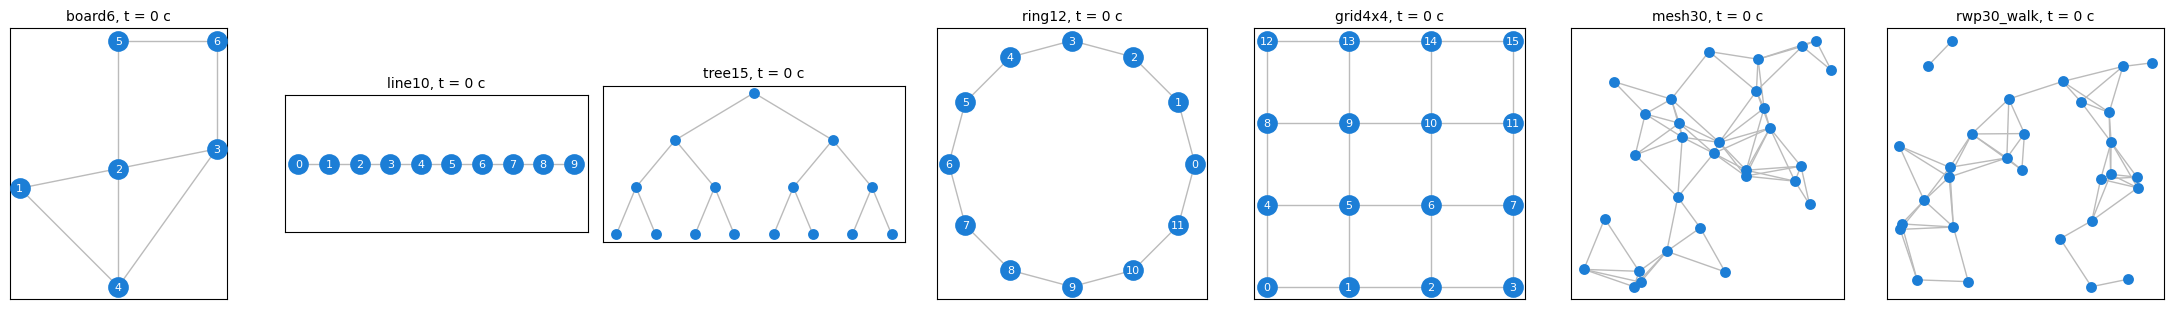

In [27]:
def draw_topology(topo, t=0.0, alive=None, path=None, ax=None, title=None, labels=True):
    alive = set(topo.nodes) if alive is None else alive
    P = topo.positions(t)
    L = topo.links(t, alive)
    ax = ax or plt.gca()
    for a, lst in L.items():
        for b, d in lst:
            if a < b:
                ax.plot([P[a][0], P[b][0]], [P[a][1], P[b][1]], color="#bbb", lw=1, zorder=1)
    if path:
        for a, b in zip(path, path[1:]):
            ax.plot([P[a][0], P[b][0]], [P[a][1], P[b][1]], color="#e8590c", lw=3, zorder=2)
    for n in topo.nodes:
        on = n in alive
        ax.scatter(*P[n], s=180 if labels else 40, zorder=3,
                   color="#1c7ed6" if on else "white", edgecolor="#1c7ed6" if on else "#e03131", lw=1.5)
        if not on:
            ax.scatter(*P[n], marker="x", color="#e03131", s=80, zorder=4)
        if labels:
            ax.text(*P[n], str(n), ha="center", va="center", fontsize=8,
                    color="white" if on else "#e03131", zorder=5)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    xs, ys = [p[0] for p in P.values()], [p[1] for p in P.values()]
    span = max(max(xs) - min(xs), max(ys) - min(ys))
    if max(ys) - min(ys) < 0.2 * span:                # вырожденная (линейная) раскладка
        cy = (max(ys) + min(ys)) / 2
        ax.set_ylim(cy - 0.25 * span, cy + 0.25 * span)
    ax.set_title(title or f"{topo.name}, t = {t:.0f} с", fontsize=10)
    return ax

_keys = ["board6", "line10", "tree15", "ring12", "grid4x4", "mesh30", "rwp30_walk"]
fig, axes = plt.subplots(1, len(_keys), figsize=(3.2 * len(_keys), 3.2))
for ax, k in zip(axes, _keys):
    draw_topology(build_topology(k, random.Random(1), 600.0), ax=ax, labels=k in ("board6", "line10", "ring12", "grid4x4"))
plt.tight_layout(); plt.show()

## 6. Динамика: пропадание и появление узлов ⚙️

Динамика работает одинаково для стационарных и подвижных топологий и складывается из двух частей.

- **Заданные события** `scheduled`: список `(узел, t_выкл, t_вкл)`. Если `t_вкл = None`, узел не возвращается. Пример: `[(2, 100, 300)]` — узел 2 пропадает на 100-й секунде и возвращается на 300-й.
- **Случайные узлы** `random_nodes`:
  - `None` — случайной динамики нет;
  - число k — k случайно выбранных узлов;
  - список — конкретные узлы;
  - `"all"` — все узлы.

  Каждый выбранный узел чередует работу и отсутствие. Длительности распределены экспоненциально со средними `mtbf_s` (работа) и `mttr_s` (отсутствие). Узлы из `protect` случайно не пропадают — обычно это источник и получатель.

Пропавший узел ничего не принимает и не передаёт. Его очередь и кэш стираются, а начатая передача обрывается.

In [28]:
@dataclass
class ChurnConfig:
    """⚙️ Пропадание и появление узлов."""
    scheduled: list = field(default_factory=list)   # [(узел, t_выкл, t_вкл или None)]
    random_nodes: object = None                      # None | k | [узлы] | "all"
    mtbf_s: float = 120.0                            # среднее время работы
    mttr_s: float = 30.0                             # среднее время отсутствия
    protect: tuple = ()                              # не пропадают случайно
    start_s: float = 0.0


def churn_events(ch: ChurnConfig, nodes, sim_time, rng):
    """Список событий (t, узел, "off" | "on")."""
    ev = []
    for n, t_off, t_on in ch.scheduled:
        ev.append((t_off, n, "off"))
        if t_on is not None:
            ev.append((t_on, n, "on"))
    pool = [n for n in nodes if n not in ch.protect]
    if ch.random_nodes is None:
        chosen = []
    elif ch.random_nodes == "all":
        chosen = pool
    elif isinstance(ch.random_nodes, int):
        chosen = rng.sample(pool, min(ch.random_nodes, len(pool)))
    else:
        chosen = [n for n in ch.random_nodes if n in pool]
    for n in chosen:
        t = ch.start_s + rng.expovariate(1 / ch.mtbf_s)
        while t < sim_time:
            ev.append((t, n, "off"))
            t += rng.expovariate(1 / ch.mttr_s)
            if t >= sim_time:
                break
            ev.append((t, n, "on"))
            t += rng.expovariate(1 / ch.mtbf_s)
    return sorted(ev)


def alive_at(events, nodes, t):
    alive = set(nodes)
    for te, n, kind in events:
        if te > t:
            break
        (alive.discard if kind == "off" else alive.add)(n)
    return alive

## 7. Трафик и сценарий ⚙️

**Трафик** — пуассоновский поток пакетов.
- `flows=[(src, dst), ...]` — заданные пары, интенсивность `rate_pps` на каждую пару.
- `flows=None` — случайные пары: для каждого пакета источник и получатель выбираются случайно, `rate_pps` — суммарная интенсивность.

Генерация прекращается за `stop_margin_s` до конца прогона, чтобы последние пакеты успели дойти.

**Сценарий** собирает всё вместе: топологию, HopLimit, размер полезной нагрузки, трафик, динамику, настройки узла, радио и канала. Если `flows` не задан, берётся поток по умолчанию из каталога топологий.

In [29]:
@dataclass
class TrafficConfig:
    flows: Optional[list] = "default"     # "default" | [(src, dst)] | None (случайные пары)
    rate_pps: float = 0.2
    start_s: float = 5.0
    stop_margin_s: float = 30.0


@dataclass
class Scenario:
    """⚙️ Сценарий эксперимента."""
    name: str
    topology: str                          # ключ из TOPOLOGIES
    sim_time_s: float = 600.0
    hop_limit: int = 7
    payload_bytes: int = 20
    traffic: TrafficConfig = field(default_factory=TrafficConfig)
    churn: ChurnConfig = field(default_factory=ChurnConfig)
    node_cfg: NodeConfig = field(default_factory=NodeConfig)
    radio: RadioConfig = field(default_factory=RadioConfig)
    channel: ChannelConfig = field(default_factory=ChannelConfig)
    topo_kwargs: dict = field(default_factory=dict)

## 8. Ядро симулятора

Дискретно-событийная модель: события (генерация пакета, начало и конец передачи, таймаут ACK, пропадание узла, сон) лежат в очереди с приоритетом по времени.

Порядок обработки передачи:
1. **Начало передачи.** Узел переходит в TX. Его текущий приём испорчен (полудуплекс). Каждый живой сосед в радиусе R получает отметку о входящем кадре. Если сосед уже что-то принимает, оба кадра помечаются как коллизия. Если сосед передаёт, спит или выключен, кадр для него потерян.
2. **Конец передачи.** Каждый сосед с неиспорченным кадром принимает его с вероятностью p(d). Кадр ставится в очередь MCU. После обработки (`t_rx_proc_s` плюс ожидание, если MCU занят) вызывается обработчик из раздела 2.
3. **Подготовка передачи.** Перед каждой передачей MCU готовит кадр за `t_tx_prep_s`.

Чтобы встроить свой алгоритм, добавьте ветку `method == "мой_метод"` в `generate` (что делает источник) и в `_on_data` (что делает узел при приёме).

In [30]:
METHODS = ("flooding", "dijkstra", "dp_hoplimit")


class Simulator:
    def __init__(self, sc: Scenario, method: str, seed: int):
        assert method in METHODS, method
        self.sc, self.method, self.seed = sc, method, seed
        self.rng = random.Random(seed)
        self.topo = build_topology(sc.topology, random.Random(seed * 7919 + 1), sc.sim_time_s, **sc.topo_kwargs)
        self.cfg, self.radio, self.ch = sc.node_cfg, sc.radio, sc.channel
        self.nodes = {n: Node(n, self.cfg, self.radio) for n in self.topo.nodes}
        self.t, self._q, self._seq = 0.0, [], itertools.count()
        self._tx_seq, self._pid_seq, self._ack_seq = itertools.count(), itertools.count(), itertools.count()
        self.active_tx, self.packets = {}, {}
        self.stats, self.air = Counter(), Counter()
        self._nbr_t, self._nbr = None, None
        self.data_toa_nominal = lora_toa(self.cfg.header_bytes + sc.payload_bytes
                                         + 4 * self.cfg.route_bytes_per_hop, self.radio)
        self.ack_toa = lora_toa(self.cfg.ack_bytes, self.radio)
        self.churn = churn_events(sc.churn, self.topo.nodes, sc.sim_time_s, random.Random(seed * 104729 + 7))

    # Очередь событий
    def at(self, t, fn, *args):
        heapq.heappush(self._q, (t, next(self._seq), fn, args))

    def run(self):
        self._schedule_traffic()
        for t, n, kind in self.churn:
            self.at(t, self._node_off if kind == "off" else self._node_on, n)
        if self.cfg.sleep_enabled:
            self._schedule_sleep()
        if math.isfinite(self.cfg.battery_j):
            self.at(1.0, self._energy_tick)
        T = self.sc.sim_time_s
        while self._q:
            t, _, fn, args = heapq.heappop(self._q)
            if t > T:
                break
            self.t = t
            fn(*args)
        self.t = T
        for nd in self.nodes.values():
            nd.set_state(nd.state, T)
        return self.summary()

    # Топология
    def alive_set(self):
        return {n for n, nd in self.nodes.items() if nd.alive}

    def _invalidate(self):
        self._nbr_t = None

    def neighbors(self, n):
        if self._nbr_t != self.t:
            self._nbr = self.topo.links(self.t, self.alive_set())
            self._nbr_t = self.t
        return self._nbr.get(n, [])

    def snapshot_graph(self):
        c0 = self.data_toa_nominal + self.cfg.mcu.t_rx_proc_s + self.cfg.mcu.t_tx_prep_s
        return {n: [(m, c0 * etx(d, self.topo.R, self.ch)) for m, d in lst]
                for n, lst in self.topo.links(self.t, self.alive_set()).items()}

    # Трафик
    def _schedule_traffic(self):
        tr = self.sc.traffic
        flows = TOPOLOGIES[self.sc.topology][1] if tr.flows == "default" else tr.flows
        t_stop = self.sc.sim_time_s - tr.stop_margin_s
        streams = [(s, d) for s, d in flows] if flows else [(None, None)]
        for s, d in streams:
            t = tr.start_s + self.rng.expovariate(tr.rate_pps)
            while t < t_stop:
                self.at(t, self.generate, s, d)
                t += self.rng.expovariate(tr.rate_pps)

    def generate(self, src, dst):
        if src is None:
            src, dst = self.rng.sample(self.topo.nodes, 2)
        node = self.nodes[src]
        if not node.alive:
            self.stats["gen_skipped_src_off"] += 1
            return
        pid = next(self._pid_seq)
        rec = dict(pid=pid, src=src, dst=dst, t_gen=self.t, t_del=None, hops=None,
                   reason=None, copy_reasons=Counter(), path_len=None)
        self.packets[pid] = rec
        H = self.sc.hop_limit
        base = self.cfg.header_bytes + self.sc.payload_bytes
        if self.method == "flooding":
            fr = Frame("DATA", pid, src, dst, H, size=base)
        else:
            g = self.snapshot_graph()
            if self.method == "dijkstra":
                path, _ = dijkstra(g, src, dst)
                why = None if path else "unreachable"
            else:
                path, _, why = dp_hoplimit(g, src, dst, H)
            if path is None:
                rec["reason"] = why                       # отказ у источника, 0 передач
                return
            rec["path_len"] = len(path) - 1
            fr = Frame("DATA", pid, src, dst, H, link_dst=path[1], route=path, idx=0,
                       size=base + len(path) * self.cfg.route_bytes_per_hop)
        node.mark_seen(pid)
        self._enqueue_now(node, fr, node.epoch)

    # Микроконтроллер: задачи выполняются по одной
    def _mcu_task(self, node, dur, fn, *args, force=False):
        """Поставить задачу MCU длительностью dur; fn(*args) — по завершении.
        False, если очередь MCU полна (force=True — для своих передач, всегда принимается)."""
        if not force and node.mcu_pending >= self.cfg.mcu.queue_capacity:
            self.stats["drop_mcu_overflow"] += 1
            return False
        start = max(self.t, node.mcu_busy_until)
        node.mcu_busy_until = start + dur
        node.mcu_active_s += dur
        node.mcu_pending += 1
        if start > self.t:
            self.stats["mcu_waits"] += 1
        self.at(start + dur, self._mcu_done, node, node.epoch, fn, args)
        return True

    def _mcu_done(self, node, epoch, fn, args):
        if node.epoch != epoch:
            return
        node.mcu_pending -= 1
        fn(*args)

    # Очередь и доступ к каналу
    def _enqueue_now(self, node, frame, epoch):
        if node.epoch != epoch or not node.alive:
            return
        if not node.enqueue(frame):
            self.stats["drop_queue_overflow"] += 1
            self._fail(frame.pid, "queue_overflow", definitive=frame.link_dst is not None)
            return
        self._kick(node)

    def _unbusy_kick(self, node, epoch):
        if node.epoch != epoch:
            return
        node.busy = False
        self._kick(node)

    def _kick(self, node):
        if node.busy or not node.queue or not node.alive or not node.awake or node.state != S.RX:
            return
        frame = node.queue[0]
        dur = lora_toa(frame.size, self.radio)
        w = node.dc_wait(self.t, dur)                    # ограничение 3
        if w > 0:
            node.busy = True
            self.stats["duty_cycle_deferrals"] += 1
            self.at(self.t + w, self._unbusy_kick, node, node.epoch)
            return
        if self.cfg.csma and node.incoming and node.csma_attempts < self.cfg.csma_max_attempts:
            node.csma_attempts += 1
            node.busy = True
            self.stats["csma_backoffs"] += 1
            self.at(self.t + self.rng.uniform(*self.cfg.csma_backoff_s), self._unbusy_kick, node, node.epoch)
            return
        node.csma_attempts = 0
        node.queue.popleft()
        node.busy = True
        self._mcu_task(node, self.cfg.mcu.t_tx_prep_s, self._tx_prepared, node, frame, dur, node.epoch, force=True)

    def _tx_prepared(self, node, frame, dur, epoch):
        """MCU подготовил кадр: запускаем передачу, если радио свободно."""
        if node.epoch != epoch or not node.alive:
            return
        if node.state != S.RX:                           # радио занято (ACK) или узел уснул
            node.queue.appendleft(frame)
            node.busy = False
            return                                       # повторный запуск — по концу ACK или пробуждению
        self._start_tx(node, frame, dur)

    # Передача
    def _start_tx(self, node, frame, dur):
        frame = replace(frame, link_src=node.id)
        node.set_state(S.TX, self.t)
        for k in node.incoming:                          # полудуплекс
            node.incoming[k] = "halfduplex"
        txid = next(self._tx_seq)
        rcv = []
        for m, d in self.neighbors(node.id):
            r = self.nodes[m]
            if not r.can_receive:
                st = "not_listening"
            elif r.incoming:                             # коллизия: портятся все
                for k in r.incoming:
                    r.incoming[k] = "collision"
                st = "collision"
            else:
                st = "ok"
            r.incoming[txid] = st
            rcv.append((m, d))
        self.active_tx[txid] = dict(sender=node.id, frame=frame, rcv=rcv, aborted=False)
        node.tx_log.append((self.t, dur)); node.airtime_s += dur; node.tx_count += 1
        self.air[frame.kind] += dur
        self.stats["tx_" + frame.kind] += 1
        self.at(self.t + dur, self._end_tx, txid, node.epoch)

    def _end_tx(self, txid, epoch):
        tx = self.active_tx.pop(txid)
        node, frame = self.nodes[tx["sender"]], tx["frame"]
        if node.epoch == epoch and node.state == S.TX:
            node.set_state(S.RX if node.awake else S.SLEEP, self.t)
        for m, d in tx["rcv"]:
            r = self.nodes[m]
            st = r.incoming.pop(txid, None)
            if st is None:
                continue
            if tx["aborted"]:
                st = "aborted"
            if st != "ok" or not r.can_receive:
                self.stats["rx_fail_" + (st if st != "ok" else "not_listening")] += 1
                continue
            if self.rng.random() > link_pdr(d, self.topo.R, self.ch):
                self.stats["rx_fail_link_loss"] += 1
                continue
            if not self._mcu_task(r, self.cfg.mcu.t_rx_proc_s, self._on_frame, r, frame, r.epoch):
                if frame.kind == "DATA":
                    self._fail(frame.pid, "mcu_overflow", definitive=False)
        if node.epoch != epoch:
            return
        if frame.kind == "DATA" and frame.link_dst is not None:   # ждём ACK
            node.current = frame
            node.ack_wait_id = next(self._ack_seq)
            m = self.cfg.mcu
            timeout = m.t_rx_proc_s + m.t_tx_prep_s + self.ack_toa + self.cfg.ack_guard_s
            self.at(self.t + timeout, self._ack_timeout, node, epoch, node.ack_wait_id)
        elif frame.kind == "DATA":
            node.busy = False
            self._kick(node)
        else:                                            # закончили ACK
            self._kick(node)

    def _send_ack(self, r, data):
        """ACK вне очереди передачи и без CSMA, но с подготовкой на MCU."""
        self._mcu_task(r, self.cfg.mcu.t_tx_prep_s, self._send_ack_now, r, data, r.epoch, force=True)

    def _send_ack_now(self, r, data, epoch):
        if r.epoch != epoch or r.state != S.RX:
            self.stats["ack_skipped_busy_radio"] += 1
            return
        ack = Frame("ACK", data.pid, r.id, data.link_src, 1, link_dst=data.link_src, size=self.cfg.ack_bytes)
        self._start_tx(r, ack, self.ack_toa)

    def _ack_timeout(self, node, epoch, wid):
        if node.epoch != epoch or node.ack_wait_id != wid:
            return
        node.ack_wait_id = None
        fr = node.current
        if node.retries < self.cfg.max_retries:
            node.retries += 1
            self.stats["retransmissions"] += 1
            node.queue.appendleft(fr)
            self.at(self.t + self.rng.uniform(*self.cfg.csma_backoff_s), self._unbusy_kick, node, epoch)
        else:
            node.retries, node.current, node.busy = 0, None, False
            self._fail(fr.pid, "link_broken", definitive=True)
            self._kick(node)

    # Приём
    def _on_frame(self, r, frame, epoch):
        if r.epoch != epoch or not r.alive:
            return
        if frame.kind == "ACK":
            cur = r.current
            if (frame.link_dst == r.id and r.ack_wait_id is not None and cur is not None
                    and frame.pid == cur.pid and frame.link_src == cur.link_dst):
                r.ack_wait_id, r.current, r.retries, r.busy = None, None, 0, False
                self._kick(r)
            return
        self._on_data(r, frame)

    def _on_data(self, r, frame):
        if self.method == "flooding":
            if not r.mark_seen(frame.pid):
                self.stats["duplicates"] += 1
                return
            if frame.dst == r.id:
                self._deliver(frame, r)
                return
            if frame.hop_limit > 1:
                fwd = replace(frame, hop_limit=frame.hop_limit - 1, hops=frame.hops + 1)
                self.at(self.t + self.rng.uniform(*self.cfg.flood_jitter_s), self._enqueue_now, r, fwd, r.epoch)
            else:
                self._fail(frame.pid, "hoplimit_exhausted", definitive=False)
            return
        # адресная передача (dijkstra, dp_hoplimit)
        if frame.link_dst != r.id:
            return                                        # чужой кадр
        self._send_ack(r, frame)
        if not r.mark_seen(frame.pid):
            self.stats["duplicates"] += 1
            return
        if frame.dst == r.id:
            self._deliver(frame, r)
            return
        if frame.hop_limit <= 1:
            self._fail(frame.pid, "hoplimit_exceeded", definitive=True)   # эфир потрачен впустую
            return
        k = frame.idx + 1
        fwd = replace(frame, hop_limit=frame.hop_limit - 1, hops=frame.hops + 1,
                      idx=k, link_dst=frame.route[k + 1])
        self._enqueue_now(r, fwd, r.epoch)

    def _deliver(self, frame, r):
        rec = self.packets[frame.pid]
        if rec["t_del"] is None:
            rec["t_del"], rec["hops"] = self.t, frame.hops + 1

    def _fail(self, pid, reason, definitive):
        rec = self.packets.get(pid)
        if rec is None or rec["t_del"] is not None:
            return
        if definitive:
            rec["reason"] = rec["reason"] or reason
        else:
            rec["copy_reasons"][reason] += 1

    # Динамика
    def _node_off(self, n):
        nd = self.nodes[n]
        if not nd.alive:
            return
        nd.set_state(S.OFF, self.t)
        nd.epoch += 1
        if nd.current is not None:
            self._fail(nd.current.pid, "node_off", definitive=True)
        for fr in nd.queue:
            self._fail(fr.pid, "node_off", definitive=fr.link_dst is not None)
        nd.reset_volatile()
        nd.mcu_busy_until = self.t
        for tx in self.active_tx.values():
            if tx["sender"] == n:
                tx["aborted"] = True
        self.stats["node_off_events"] += 1
        self._invalidate()

    def _node_on(self, n):
        nd = self.nodes[n]
        if nd.state != S.OFF:
            return
        nd.set_state(S.RX if nd.awake else S.SLEEP, self.t)
        self._invalidate()

    def _energy_tick(self):
        for n, nd in self.nodes.items():
            if nd.alive:
                nd.set_state(nd.state, self.t)
                if nd.battery_empty(self.t):
                    self._node_off(n)
                    nd.state, nd.t_death = S.DEAD, self.t
                    self.stats["battery_deaths"] += 1
        self.at(self.t + 1.0, self._energy_tick)

    # 3*. Сон
    def _schedule_sleep(self):
        P, f = self.cfg.sleep_period_s, self.cfg.awake_fraction
        for n in self.nodes:
            phase = self.rng.uniform(0, P)
            k = 0
            while True:
                t_sleep = k * P - phase + f * P
                t_wake = (k + 1) * P - phase
                if t_sleep > self.sc.sim_time_s:
                    break
                if t_sleep >= 0:
                    self.at(t_sleep, self._sleep_toggle, n, False)
                if t_wake >= 0:
                    self.at(t_wake, self._sleep_toggle, n, True)
                k += 1

    def _sleep_toggle(self, n, awake):
        nd = self.nodes[n]
        nd.awake = awake
        if not nd.alive:
            return
        if not awake and nd.state == S.RX:
            for k in nd.incoming:
                nd.incoming[k] = "not_listening"
            nd.set_state(S.SLEEP, self.t)
        elif awake and nd.state == S.SLEEP:
            nd.set_state(S.RX, self.t)
            self._kick(nd)

    # Итоги
    def packets_df(self):
        rows = []
        for r in self.packets.values():
            if r["t_del"] is not None:
                outcome = "delivered"
            elif r["reason"]:
                outcome = r["reason"]
            elif r["copy_reasons"]:
                outcome = r["copy_reasons"].most_common(1)[0][0]
            else:
                outcome = "lost_in_channel"
            rows.append(dict(pid=r["pid"], src=r["src"], dst=r["dst"], t_gen=r["t_gen"],
                             latency_s=(r["t_del"] - r["t_gen"]) if r["t_del"] is not None else None,
                             hops=r["hops"], outcome=outcome))
        return pd.DataFrame(rows)

    def summary(self):
        pk = self.packets_df()
        gen = len(pk)
        dl = pk[pk.outcome == "delivered"] if gen else pk
        air_total = sum(self.air.values())
        T = self.sc.sim_time_s
        out = dict(scenario=self.sc.name, topology=self.sc.topology, kind=self.topo.kind,
                   method=self.method, seed=self.seed, hop_limit=self.sc.hop_limit,
                   generated=gen, delivered=len(dl),
                   pdr=len(dl) / gen if gen else float("nan"),
                   latency_mean_s=dl.latency_s.mean() if len(dl) else float("nan"),
                   latency_p95_s=dl.latency_s.quantile(0.95) if len(dl) else float("nan"),
                   airtime_total_s=air_total,
                   airtime_per_delivered_s=air_total / len(dl) if len(dl) else float("nan"),
                   tx_per_delivered=(self.stats["tx_DATA"] + self.stats["tx_ACK"]) / len(dl) if len(dl) else float("nan"),
                   overhead_share=self.air["ACK"] / air_total if air_total else 0.0,
                   energy_total_j=sum(n.total_energy_j(T) for n in self.nodes.values()),
                   energy_radio_j=sum(n.energy_j for n in self.nodes.values()),
                   energy_mcu_j=sum(n.mcu_energy_j(T) for n in self.nodes.values()),
                   energy_max_node_j=max(n.total_energy_j(T) for n in self.nodes.values()),
                   mcu_util_max=max(n.mcu_active_s for n in self.nodes.values()) / T,
                   mcu_waits=self.stats["mcu_waits"],
                   max_node_duty=max(n.airtime_s for n in self.nodes.values()) / self.sc.sim_time_s,
                   battery_deaths=self.stats["battery_deaths"],
                   collisions_rx=self.stats["rx_fail_collision"],
                   retransmissions=self.stats["retransmissions"],
                   duty_cycle_deferrals=self.stats["duty_cycle_deferrals"])
        if gen:
            for reason, cnt in pk.outcome.value_counts().items():
                if reason != "delivered":
                    out["fail_" + reason] = cnt
        return out


def simulate(sc: Scenario, method: str, seed: int = 1):
    sim = Simulator(sc, method, seed)
    res = sim.run()
    return res, sim

## 9. Метрики и графики

| Метрика | Смысл |
|---|---|
| `pdr` | Доля доставленных пакетов |
| `latency_mean_s`, `latency_p95_s` | Задержка доставки: средняя и 95-й перцентиль |
| `airtime_per_delivered_s` | Суммарное эфирное время всех узлов на один доставленный пакет — главный показатель расхода эфира |
| `tx_per_delivered` | Передач (DATA + ACK) на доставленный пакет |
| `overhead_share` | Доля служебного трафика (ACK) в эфирном времени |
| `energy_total_j`, `energy_max_node_j` | Энергия (радио + MCU): суммарная и самого нагруженного узла |
| `energy_radio_j`, `energy_mcu_j` | Раздельный расход радио и микроконтроллера |
| `mcu_util_max`, `mcu_waits` | Максимальная загрузка MCU среди узлов; сколько задач ждали освобождения MCU |
| `max_node_duty` | Максимальная доля времени в передаче среди узлов |
| `fail_*` | Причины недоставки: `unreachable`, `hoplimit_insufficient` (отказ у источника), `hoplimit_exceeded` / `hoplimit_exhausted` (эфир потрачен), `link_broken`, `queue_overflow`, `mcu_overflow`, `node_off`, `lost_in_channel` |

In [34]:
def run_matrix(scenarios, methods=METHODS, seeds=range(1, 6), verbose=True):
    rows = []
    for sc in scenarios:
        for m in methods:
            for s in seeds:
                res, _ = simulate(sc, m, s)
                rows.append(res)
        if verbose:
            print(f"готово: {sc.name}")
    return pd.DataFrame(rows).fillna({c: 0 for c in pd.DataFrame(rows).columns if c.startswith("fail_")})


def aggregate(df, by=("scenario", "method"),
              cols=("pdr", "airtime_per_delivered_s", "latency_mean_s", "tx_per_delivered", "overhead_share", "energy_total_j")):
    """Среднее ± стандартное отклонение по повторам."""
    g = df.groupby(list(by))[list(cols)]
    mean, std = g.mean(), g.std().fillna(0)
    out = mean.copy()
    for c in cols:
        out[c] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(mean[c], std[c])]
    return out


def plot_compare(df, x="scenario", metrics=("pdr", "airtime_per_delivered_s", "latency_mean_s"), title=""):
    fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 3.6))
    xs = list(dict.fromkeys(df[x]))
    methods = list(dict.fromkeys(df["method"]))
    w = 0.8 / len(methods)
    colors = {"flooding": "#1c7ed6", "dijkstra": "#e8590c", "dp_hoplimit": "#2f9e44"}
    for ax, met in zip(axes, metrics):
        for i, m in enumerate(methods):
            sub = df[df.method == m].groupby(x)[met]
            mean, std = sub.mean().reindex(xs), sub.std().reindex(xs).fillna(0)
            pos = [j + (i - (len(methods) - 1) / 2) * w for j in range(len(xs))]
            ax.bar(pos, mean, w, yerr=std, capsize=3, label=m, color=colors.get(m))
        ax.set_xticks(range(len(xs))); ax.set_xticklabels(xs, rotation=20, ha="right", fontsize=8)
        ax.set_title(met, fontsize=10); ax.grid(axis="y", alpha=.3)
    axes[0].legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()


def plot_snapshots(sc: Scenario, seed=1, times=(0, 150, 300, 450)):
    sim = Simulator(sc, "flooding", seed)
    fig, axes = plt.subplots(1, len(times), figsize=(3.6 * len(times), 3.6))
    for ax, t in zip(axes, times):
        draw_topology(sim.topo, t=t, alive=alive_at(sim.churn, sim.topo.nodes, t), ax=ax,
                      labels=len(sim.topo.nodes) <= 16)
    plt.tight_layout(); plt.show()

## 10. Эксперименты

### 10.1. Граф с доски: поток 1 → 6, стационарная сеть

Три пути по 3 перехода: 1–2–5–6, 1–2–3–6, 1–4–3–6. Каналы разной длины, поэтому стоимость путей разная. Оракульные методы выбирают самый дешёвый.

Затопление здесь теряет около половины пакетов. Узлы 3 и 5 — соседи получателя 6, но друг друга не слышат: это скрытые узлы. Прослушивание канала их не спасает, и их ретрансляции сталкиваются у узла 6. Попробуйте увеличить окно задержки: `NodeConfig(flood_jitter_s=(0, 0.5))`.

Маршрут Дейкстры 1 → 6: 1 → 2 → 3 → 6 стоимость 256.5 мс эфира


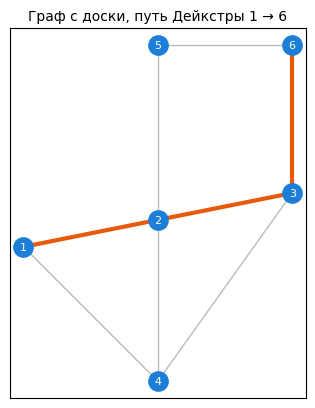

готово: board: норма


pdr airtime_per_delivered_s latency_mean_s tx_per_delivered overhead_share  energy_total_j
scenario     method                                                                                                           
board: норма dijkstra     0.981 ± 0.009           0.378 ± 0.013  0.369 ± 0.017    6.584 ± 0.191  0.300 ± 0.005  69.339 ± 1.920
             dp_hoplimit  0.981 ± 0.009           0.378 ± 0.013  0.369 ± 0.017    6.584 ± 0.191  0.300 ± 0.005  69.339 ± 1.920
             flooding     0.476 ± 0.062           0.729 ± 0.103  0.407 ± 0.006   10.138 ± 1.429  0.000 ± 0.000  68.129 ± 1.416

In [33]:
sc_board = Scenario("board: норма", "board6", hop_limit=7)
sim = Simulator(sc_board, "dijkstra", 1)
path, cost = dijkstra(sim.snapshot_graph(), 1, 6)
print("Маршрут Дейкстры 1 → 6:", " → ".join(map(str, path)), f"стоимость {cost * 1000:.1f} мс эфира")
draw_topology(sim.topo, path=path, title="Граф с доски, путь Дейкстры 1 → 6"); plt.show()

df_board = run_matrix([sc_board], seeds=range(1, 6))
aggregate(df_board)

### 10.2. Граф с доски: узел 2 пропадает, недостаточный HopLimit

- **Отказ узла 2** с 100-й по 300-ю секунду. Узел 2 — центральный, через него идут два пути из трёх.
- **HopLimit = 2.** Для потока 1 → 6 нужно минимум 3 перехода. DP отказывает сразу у источника, тратя 0 эфира. Дейкстра отправляет пакет и теряет его после двух передач. Затопление тоже тратит эфир впустую.

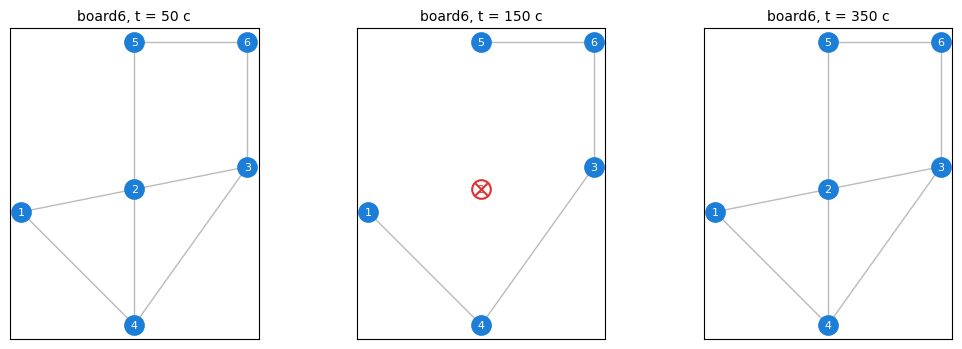

готово: board: норма
готово: board: узел 2 пропал 100–300 с
готово: board: HopLimit = 2


pdr airtime_per_delivered_s latency_mean_s tx_per_delivered overhead_share  energy_total_j
scenario                       method                                                                                                           
board: HopLimit = 2            dijkstra     0.000 ± 0.000             nan ± 0.000    nan ± 0.000      nan ± 0.000  0.306 ± 0.005  64.585 ± 1.163
                               dp_hoplimit  0.000 ± 0.000             nan ± 0.000    nan ± 0.000      nan ± 0.000  0.000 ± 0.000  54.684 ± 0.000
                               flooding     0.000 ± 0.000             nan ± 0.000    nan ± 0.000      nan ± 0.000  0.000 ± 0.000  62.873 ± 0.850
board: норма                   dijkstra     0.981 ± 0.009           0.378 ± 0.013  0.369 ± 0.017    6.584 ± 0.191  0.300 ± 0.005  69.339 ± 1.920
                               dp_hoplimit  0.981 ± 0.009           0.378 ± 0.013  0.369 ± 0.017    6.584 ± 0.191  0.300 ± 0.005  69.339 ± 1.920
                               flooding     0.476 ± 0.062           0.729 ± 0.103  0.407 ± 0.006   10.138 ± 1.429  0.000 ± 0.000  68.129 ± 1.416
board: узел 2 пропал 100–300 с dijkstra     0.968 ± 0.013           0.432 ± 0.018  0.385 ± 0.018    7.407 ± 0.269  0.283 ± 0.006  68.115 ± 1.918
                               dp_hoplimit  0.968 ± 0.013           0.432 ± 0.018  0.385 ± 0.018    7.407 ± 0.269  0.283 ± 0.006  68.115 ± 1.918
                               flooding     0.567 ± 0.044           0.505 ± 0.044  0.424 ± 0.015    7.021 ± 0.614  0.000 ± 0.000  62.840 ± 1.156

fail_lost_in_channel  fail_link_broken  fail_hoplimit_exhausted  fail_hoplimit_exceeded  fail_hoplimit_insufficient  airtime_total_s
scenario                       method                                                                                                                                           
board: HopLimit = 2            dijkstra                      0.0               1.2                      0.0                   103.4                         0.0            26.27
                               dp_hoplimit                   0.0               0.0                      0.0                     0.0                       104.6             0.00
                               flooding                      0.6               0.0                    104.0                     0.0                         0.0            21.77
board: норма                   dijkstra                      0.0               2.0                      0.0                     0.0                         0.0            38.90
                               dp_hoplimit                   0.0               2.0                      0.0                     0.0                         0.0            38.90
                               flooding                     54.4               0.0                      0.0                     0.0                         0.0            35.78
board: узел 2 пропал 100–300 с dijkstra                      0.0               3.4                      0.0                     0.0                         0.0            43.77
                               dp_hoplimit                   0.0               3.4                      0.0                     0.0                         0.0            43.77
                               flooding                     45.0               0.0                      0.0                     0.0                         0.0            29.81

In [32]:
sc_board_fail = Scenario("board: узел 2 пропал 100–300 с", "board6",
                         churn=ChurnConfig(scheduled=[(2, 100, 300)]))
sc_board_h2 = Scenario("board: HopLimit = 2", "board6", hop_limit=2)

plot_snapshots(sc_board_fail, times=(50, 150, 350))
df_board2 = run_matrix([sc_board, sc_board_fail, sc_board_h2], seeds=range(1, 6))
display(aggregate(df_board2))
fail_cols = [c for c in df_board2.columns if c.startswith("fail_")]
display(df_board2.groupby(["scenario", "method"])[fail_cols + ["airtime_total_s"]].mean().round(2))

### 10.3. Все стационарные топологии: норма и случайная динамика

В варианте со случайной динамикой три случайных узла (кроме источника и получателя) в среднем работают 120 с и отсутствуют 30 с.

готово: board6
готово: board6+churn
готово: line10
готово: line10+churn
готово: tree15
готово: tree15+churn
готово: ring12
готово: ring12+churn
готово: grid4x4
готово: grid4x4+churn
готово: mesh30
готово: mesh30+churn


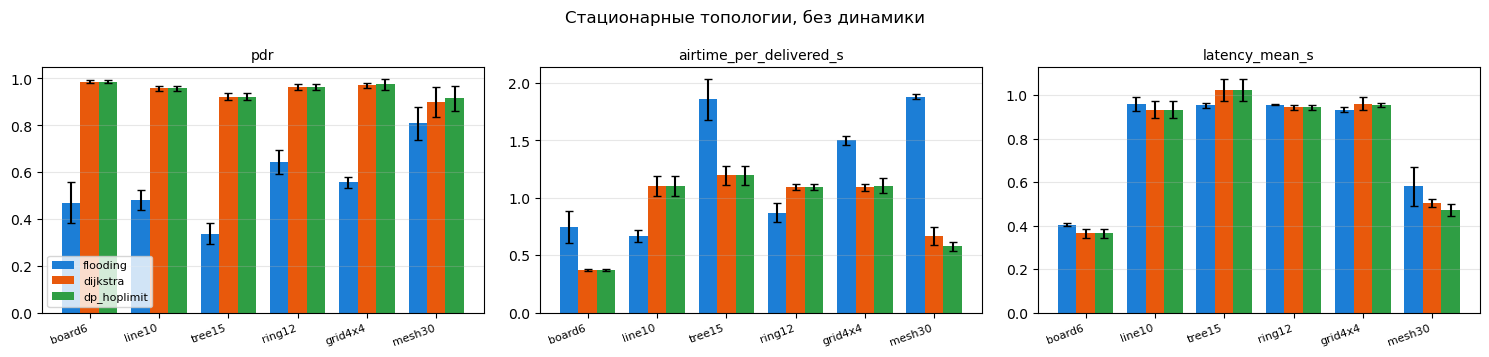

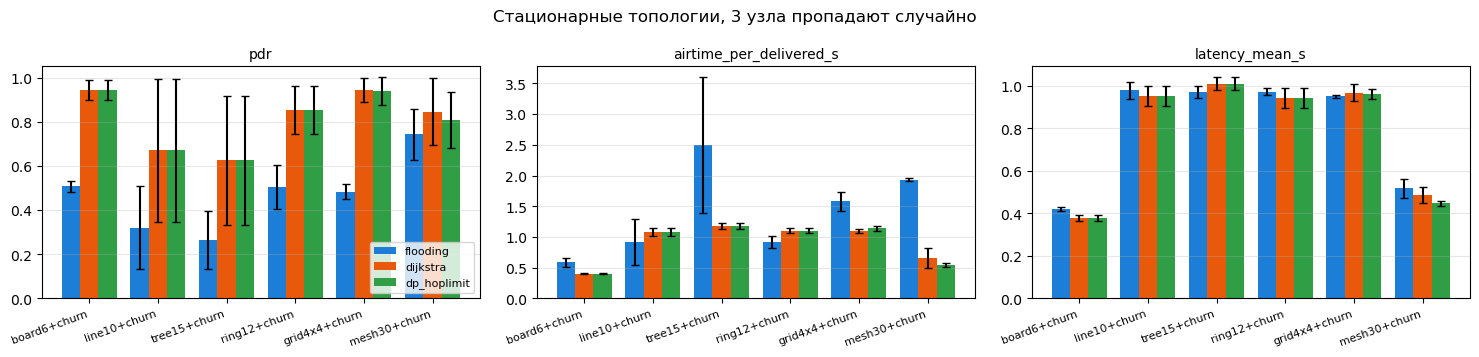

In [35]:
static_keys = ["board6", "line10", "tree15", "ring12", "grid4x4", "mesh30"]
scs = []
for k in static_keys:
    flows = TOPOLOGIES[k][1]
    protect = tuple(x for f in flows for x in f) if flows else ()
    scs.append(Scenario(f"{k}", k))
    scs.append(Scenario(f"{k}+churn", k, churn=ChurnConfig(random_nodes=3, mtbf_s=120, mttr_s=30, protect=protect)))

df_static = run_matrix(scs, seeds=range(1, 4))
plot_compare(df_static[~df_static.scenario.str.contains("churn")], title="Стационарные топологии, без динамики")
plot_compare(df_static[df_static.scenario.str.contains("churn")], title="Стационарные топологии, 3 узла пропадают случайно")

### 10.4. Подвижные сети: влияние скорости

30 узлов в квадрате 2500 × 2500 м, случайные пары, суммарно 0,2 пакета/с. Сравниваются пешеходы, техника и дроны, с динамикой и без. В динамическом варианте каждый узел в среднем работает 300 с и отсутствует 30 с.

Как читать результат. Оракульные методы вычисляют маршрут у источника в момент отправки, а доставка занимает около 0,3–0,5 с. За это время даже дрон смещается на 5–10 м, поэтому маршрут почти не устаревает: `fail_link_broken` — единицы пакетов.

Основные потери в подвижной сети другие:
- моменты, когда сеть распадается на части (`fail_unreachable`);
- коллизии при затоплении (`fail_lost_in_channel`).

Устаревание маршрута станет главным фактором для алгоритма, который запоминает путь на время (например, гибрид «затопление → next-hop»). Именно такой алгоритм стоит проверять на этих сценариях.

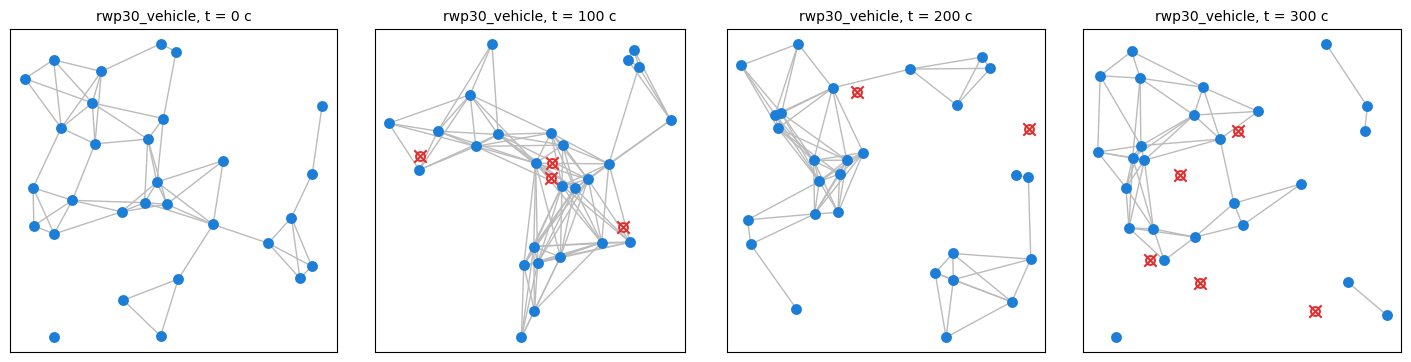

готово: rwp30_walk
готово: rwp30_walk+churn
готово: rwp30_vehicle
готово: rwp30_vehicle+churn
готово: rwp30_drone
готово: rwp30_drone+churn


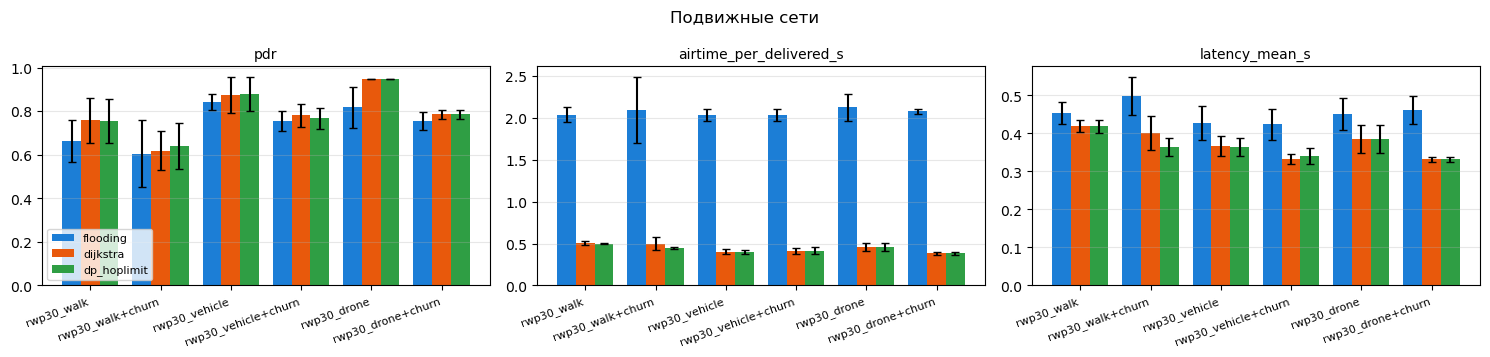

pdr airtime_per_delivered_s latency_mean_s tx_per_delivered overhead_share    energy_total_j
scenario            method                                                                                                             
rwp30_drone         dijkstra     0.947 ± 0.001           0.461 ± 0.049  0.385 ± 0.036    7.591 ± 0.737  0.261 ± 0.010   290.131 ± 1.168
                    dp_hoplimit  0.947 ± 0.001           0.461 ± 0.049  0.385 ± 0.036    7.591 ± 0.737  0.261 ± 0.010   290.131 ± 1.168
                    flooding     0.818 ± 0.093           2.124 ± 0.157  0.450 ± 0.042   29.532 ± 2.181  0.000 ± 0.000  339.731 ± 10.753
rwp30_drone+churn   dijkstra     0.786 ± 0.020           0.381 ± 0.015  0.332 ± 0.007    6.362 ± 0.272  0.266 ± 0.008   259.344 ± 5.316
                    dp_hoplimit  0.786 ± 0.020           0.381 ± 0.015  0.332 ± 0.007    6.362 ± 0.272  0.266 ± 0.008   259.344 ± 5.316
                    flooding     0.755 ± 0.041           2.079 ± 0.031  0.461 ± 0.036   28.895 ± 0.432  0.000 ± 0.000   302.950 ± 9.713
rwp30_vehicle       dijkstra     0.873 ± 0.083           0.403 ± 0.029  0.366 ± 0.026    6.704 ± 0.458  0.265 ± 0.004   286.887 ± 0.431
                    dp_hoplimit  0.880 ± 0.078           0.398 ± 0.021  0.365 ± 0.023    6.624 ± 0.340  0.265 ± 0.004   286.831 ± 0.524
                    flooding     0.841 ± 0.036           2.035 ± 0.072  0.426 ± 0.044   28.287 ± 1.004  0.000 ± 0.000   338.641 ± 4.293
rwp30_vehicle+churn dijkstra     0.780 ± 0.054           0.409 ± 0.039  0.332 ± 0.014    6.773 ± 0.622  0.260 ± 0.010   260.092 ± 4.029
                    dp_hoplimit  0.768 ± 0.048           0.413 ± 0.041  0.342 ± 0.021    6.830 ± 0.645  0.258 ± 0.006   259.986 ± 3.896
                    flooding     0.757 ± 0.046           2.032 ± 0.068  0.423 ± 0.041   28.243 ± 0.939  0.000 ± 0.000   302.131 ± 8.757
rwp30_walk          dijkstra     0.759 ± 0.104           0.507 ± 0.020  0.419 ± 0.016    8.313 ± 0.266  0.258 ± 0.009   288.307 ± 3.512
                    dp_hoplimit  0.756 ± 0.102           0.499 ± 0.008  0.418 ± 0.017    8.202 ± 0.076  0.258 ± 0.007   287.985 ± 3.034
                    flooding     0.663 ± 0.097           2.036 ± 0.090  0.453 ± 0.029   28.298 ± 1.245  0.000 ± 0.000  325.192 ± 11.055
rwp30_walk+churn    dijkstra     0.618 ± 0.090           0.500 ± 0.076  0.401 ± 0.044    8.161 ± 1.103  0.255 ± 0.012   259.468 ± 5.401
                    dp_hoplimit  0.639 ± 0.106           0.451 ± 0.011  0.364 ± 0.024    7.442 ± 0.208  0.260 ± 0.003   258.528 ± 4.115
                    flooding     0.605 ± 0.152           2.097 ± 0.393  0.498 ± 0.051   29.145 ± 5.466  0.000 ± 0.000   290.418 ± 8.948

fail_lost_in_channel  fail_hoplimit_exhausted  fail_unreachable  fail_link_broken  fail_hoplimit_exceeded  fail_hoplimit_insufficient
scenario            method                                                                                                                                            
rwp30_drone         dijkstra                      0.0                      0.0               4.3               1.0                     0.0                         0.0
                    dp_hoplimit                   0.0                      0.0               4.3               1.0                     0.0                         0.0
                    flooding                     16.3                      1.7               0.0               0.0                     0.0                         0.0
rwp30_drone+churn   dijkstra                      0.0                      0.0              18.7               1.3                     0.0                         0.0
                    dp_hoplimit                   0.0                      0.0              18.7               1.3                     0.0                         0.0
                    flooding                     19.7                      3.0               0.0               0.0                     0.0                         0.0
rwp30_vehicle       dijkstra                      0.0                      0.0              10.3               2.7                     0.3                         0.0
                    dp_hoplimit                   0.0                      0.0              10.3               2.0                     0.0                         0.3
                    flooding                     13.7                      2.7               0.0               0.0                     0.0                         0.0
rwp30_vehicle+churn dijkstra                      0.0                      0.0              20.3               0.7                     0.3                         0.0
                    dp_hoplimit                   0.0                      0.0              21.0               1.0                     0.0                         0.3
                    flooding                     20.3                      2.3               0.0               0.0                     0.0                         0.0
rwp30_walk          dijkstra                      0.0                      0.0              22.0               2.0                     0.3                         0.0
                    dp_hoplimit                   0.0                      0.0              22.3               2.0                     0.0                         0.3
                    flooding                     30.7                      3.0               0.0               0.0                     0.0                         0.0
rwp30_walk+churn    dijkstra                      0.0                      0.0              32.0               1.0                     1.3                         0.0
                    dp_hoplimit                   0.0                      0.0              31.0               0.3                     0.0                         0.7
                    flooding                     30.3                      5.0               0.0               0.0                     0.0                         0.0

In [36]:
mob_keys = ["rwp30_walk", "rwp30_vehicle", "rwp30_drone"]
scs_mob = []
for k in mob_keys:
    scs_mob.append(Scenario(k, k))
    scs_mob.append(Scenario(k + "+churn", k, churn=ChurnConfig(random_nodes="all", mtbf_s=300, mttr_s=30)))

plot_snapshots(Scenario("rwp30_vehicle+churn", "rwp30_vehicle",
                        churn=ChurnConfig(random_nodes="all", mtbf_s=300, mttr_s=30)), times=(0, 100, 200, 300))
df_mob = run_matrix(scs_mob, seeds=range(1, 4))
plot_compare(df_mob, metrics=("pdr", "airtime_per_delivered_s", "latency_mean_s"), title="Подвижные сети")
display(aggregate(df_mob))
fail_cols = [c for c in df_mob.columns if c.startswith("fail_")]
df_mob.groupby(["scenario", "method"])[fail_cols].mean().round(1)

### 10.5. Ограничения узла в действии

- **Энергия.** Бюджет 25 Дж. Дежурный приём SX1262 при 3,3 В и 4,6 мА расходует около 15 мДж/с, поэтому узлы умирают примерно через 27 минут. Прогон длится 30 минут.
- **Микроконтроллер.** Медленный MCU (20 мс на обработку, очередь 4 задачи) и ESP32-S3: у него время короче, зато в простое он потребляет заметно больше nRF52840.
- **Память.** Очередь в 2 пакета при высокой нагрузке.
- **Эфир.** Лимит 1 %, как в EU868.
- **Сон (3\*).** Узел бодрствует 50 % времени. Расписания узлов не синхронизированы, поэтому многие кадры приходят спящим соседям.

Обратите внимание: в базовых настройках действует лимит эфира 10 %. При 0,5 пакета/с узлы на пути DP подходят к лимиту из-за повторов, поэтому задержка растёт до десятков секунд.

Всё проверяется на решётке 4 × 4 с затоплением и DP.

In [37]:
base = dict(topology="grid4x4", traffic=TrafficConfig(rate_pps=0.5))
scs_lim = [
    Scenario("без ограничений", node_cfg=NodeConfig(duty_cycle_limit=1.0), **base),
    Scenario("базовые настройки (эфир 10 %)", **base),
    Scenario("энергия 25 Дж, 30 мин", sim_time_s=1800, node_cfg=NodeConfig(battery_j=25), **base),
    Scenario("медленный MCU", node_cfg=NodeConfig(mcu=MCU_PRESETS["slow_mcu"]), **base),
    Scenario("MCU ESP32-S3", node_cfg=NodeConfig(mcu=MCU_PRESETS["ESP32-S3"]), **base),
    Scenario("очередь 2 пакета", node_cfg=NodeConfig(queue_capacity=2), **base),
    Scenario("эфир 1 %", node_cfg=NodeConfig(duty_cycle_limit=0.01), **base),
    Scenario("сон 50 %", node_cfg=NodeConfig(sleep_enabled=True, awake_fraction=0.5), **base),
]
df_lim = run_matrix(scs_lim, methods=("flooding", "dp_hoplimit"), seeds=range(1, 4))
cols = ["pdr", "latency_mean_s", "airtime_per_delivered_s", "energy_radio_j", "energy_mcu_j",
        "battery_deaths", "duty_cycle_deferrals", "mcu_util_max", "mcu_waits"]
fail_cols = [c for c in df_lim.columns if c.startswith("fail_")]
df_lim.groupby(["scenario", "method"], sort=False)[cols + fail_cols].mean().round(3)

готово: без ограничений
готово: базовые настройки (эфир 10 %)
готово: энергия 25 Дж, 30 мин
готово: медленный MCU
готово: MCU ESP32-S3
готово: очередь 2 пакета
готово: эфир 1 %
готово: сон 50 %


pdr  latency_mean_s  airtime_per_delivered_s  energy_radio_j  energy_mcu_j  battery_deaths  duty_cycle_deferrals  mcu_util_max  \
scenario                      method                                                                                                                                          
без ограничений               flooding     0.457           0.947                    1.660         225.671         0.387             0.0                 0.000         0.004   
                              dp_hoplimit  0.918           1.158                    1.213         263.402         0.638             0.0                 0.000         0.011   
базовые настройки (эфир 10 %) flooding     0.457           0.947                    1.660         225.671         0.387             0.0                 0.000         0.004   
                              dp_hoplimit  0.843          18.435                    1.235         255.726         0.604             0.0               634.000         0.010   
энергия 25 Дж, 30 мин         flooding     0.493           0.940                    1.570         399.485         0.650            16.0                 0.000         0.002   
                              dp_hoplimit  0.817          16.792                    1.287         399.583         0.724            16.0               793.000         0.003   
медленный MCU                 flooding     0.507           1.095                    1.542         227.896         2.636             0.0                 0.000         0.021   
                              dp_hoplimit  0.794          19.201                    1.381         261.433         4.128             0.0               651.333         0.047   
MCU ESP32-S3                  flooding     0.499           0.920                    1.531         226.470        27.363             0.0                 0.000         0.002   
                              dp_hoplimit  0.873          16.371                    1.185         255.082        28.823             0.0               711.667         0.005   
очередь 2 пакета              flooding     0.455           0.952                    1.688         226.811         0.395             0.0                 0.000         0.004   
                              dp_hoplimit  0.819           1.748                    1.167         246.737         0.580             0.0               131.000         0.010   
эфир 1 %                      flooding     0.129          98.255                    1.552         166.824         0.174             0.0                85.000         0.001   
                              dp_hoplimit  0.079         242.296                    1.377         157.103         0.149             0.0               204.333         0.001   
сон 50 %                      flooding     0.124           4.904                    2.940         104.853         0.184             0.0                 0.000         0.002   
                              dp_hoplimit  0.109          32.110                    3.372         135.471         0.270             0.0               439.667         0.005   

                                           mcu_waits  fail_lost_in_channel  fail_hoplimit_exhausted  fail_link_broken  fail_queue_overflow  fail_node_off  
scenario                      method                                                                                                                       
без ограничений               flooding        17.333               127.333                   26.000             0.000                0.000          0.000  
                              dp_hoplimit   1313.333                 0.000                    0.000            23.000                0.000          0.000  
базовые настройки (эфир 10 %) flooding        17.333               127.333                   26.000             0.000                0.000          0.000  
                              dp_hoplimit    992.667                 0.333                    0.000            24.

### 10.6. Полная матрица и сохранение результатов

Шаблон для отчёта: все топологии × сценарии × методы × повторы. Результаты сохраняются в `results_runs.csv` (каждый прогон) и `results_summary.csv` (средние). Отключено по умолчанию: поставьте `RUN_FULL = True`.

In [17]:
RUN_FULL = False

if RUN_FULL:
    full = []
    for k in static_keys + mob_keys:
        flows = TOPOLOGIES[k][1]
        protect = tuple(x for f in flows for x in f) if flows else ()
        full += [
            Scenario(f"{k} | норма", k),
            Scenario(f"{k} | динамика", k, churn=ChurnConfig(random_nodes=3, protect=protect)),
            Scenario(f"{k} | HopLimit 3", k, hop_limit=3),
        ]
    df_full = run_matrix(full, seeds=range(1, 6))
    df_full.to_csv("results_runs.csv", index=False)
    summary = df_full.groupby(["scenario", "method"]).mean(numeric_only=True)
    summary.to_csv("results_summary.csv")
    display(summary[["pdr", "airtime_per_delivered_s", "latency_mean_s", "overhead_share"]].round(3))

## Что дальше

- **Свой алгоритм на локальной информации.** Добавьте имя в `METHODS`. Затем добавьте ветку в `Simulator.generate` (что делает источник) и в `Simulator._on_data` (что делает узел при приёме). Узлу доступны только его соседи (`self.neighbors(r.id)` — то, что он слышит), заголовок кадра и его собственное состояние. Полную карту `snapshot_graph()` используют только эталонные методы.
- **Модуль выбора метода.** Берёт агрегированную таблицу из `run_matrix`, отбрасывает методы с `pdr` ниже порога и выбирает минимум взвешенной суммы нормированных `airtime_per_delivered_s`, `latency_mean_s` и `overhead_share`.
- **Эффект захвата, ослабление сигнала, SNR.** Заменить `link_pdr` и правило коллизий в `_start_tx`.